<a href="https://colab.research.google.com/github/apatidar2905/ML-data-preprocessing/blob/main/data_balancing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#What is Data Balancing?
#Data balancing is a technique used in Machine Learning to make the number of observations in different classes more equal.
#It is mainly used when we have an imbalanced dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = {
    'Transaction_Amount': [100, 200, 150, 300, 250, 400, 120, 180, 500, 600,
                           110, 220, 170, 350, 280, 450, 130, 190, 550, 650],
    'Customer_Age': [22, 25, 30, 35, 28, 40, 24, 29, 45, 50,
                     23, 26, 31, 36, 27, 41, 25, 30, 46, 52],
    'Transaction_Type': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
                         0, 0, 0, 0, 0, 0, 0, 0, 1, 1]
}

df = pd.DataFrame(data)

df.head()

,Transaction_Amount,Customer_Age,Transaction_Type
0,100,22,0
1,200,25,0
2,150,30,0
3,300,35,0
4,250,28,0


In [3]:
#Check Class Distribution
print(df['Transaction_Type'].value_counts())

Transaction_Type
0    18
1     2
Name: count, dtype: int64


In [4]:
#Check Class Percentage
print(df['Transaction_Type'].value_counts(normalize=True) * 100)

Transaction_Type
0    90.0
1    10.0
Name: proportion, dtype: float64


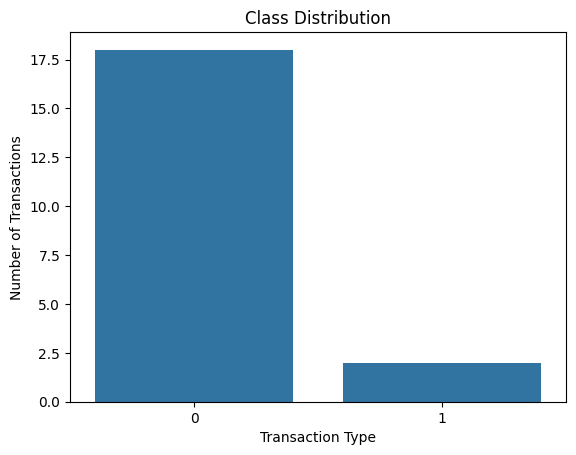

In [5]:
#Visualize Class Distribution
sns.countplot(x='Transaction_Type', data=df)

plt.title("Class Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.show()

In [ ]:
#Techniques of Data Balancing
#There are three important techniques you should learn first:
#1. Random Over Sampling
#2. Random Under Sampling
#3. SMOTE

In [6]:
#1 Random Over Sampling is a technique that increases the number of records in the minority class.
#It works by randomly selecting existing minority-class observations and duplicating them
!pip install imbalanced-learn

In [11]:
from imblearn.over_sampling import RandomOverSampler
X = df.drop('Transaction_Type', axis=1)#it contains input fature
print("x=",X)
y = df['Transaction_Type']#contain target variable
print("y=",y)

x=     Transaction_Amount  Customer_Age
0                  100            22
1                  200            25
2                  150            30
3                  300            35
4                  250            28
5                  400            40
6                  120            24
7                  180            29
8                  500            45
9                  600            50
10                 110            23
11                 220            26
12                 170            31
13                 350            36
14                 280            27
15                 450            41
16                 130            25
17                 190            30
18                 550            46
19                 650            52
y= 0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    1
19    1
Name: Transaction_Type, dtype: int64


In [13]:
#Create RandomOverSampler Object
ros = RandomOverSampler(random_state=42)
print("ros=",ros)

#Apply Random Over Sampling
X_over, y_over = ros.fit_resample(X, y)
print("applying random sampling=",X_over,y_over)

#check result
print("Before Balancing:")
print(y.value_counts())

print("\nAfter Balancing:")
print(y_over.value_counts())

#Important Points
# It duplicates existing minority-class records.
# It increases dataset size.
# It can cause overfitting because duplicated records do not provide new information.

ros= RandomOverSampler(random_state=42)
applying random sampling=     Transaction_Amount  Customer_Age
0                  100            22
1                  200            25
2                  150            30
3                  300            35
4                  250            28
5                  400            40
6                  120            24
7                  180            29
8                  500            45
9                  600            50
10                 110            23
11                 220            26
12                 170            31
13                 350            36
14                 280            27
15                 450            41
16                 130            25
17                 190            30
18                 550            46
19                 650            52
20                 550            46
21                 650            52
22                 550            46
23                 550            46
24       

In [15]:
#Technique 2: Random Under Sampling
#Random Under Sampling is a technique that reduces the number of records in the majority class.
#It works by randomly removing some observations from the majority class
from imblearn.under_sampling import RandomUnderSampler

#create object
rus = RandomUnderSampler(random_state=42)

#apply under sampling
X_under, y_under = rus.fit_resample(X, y)

#check result
print("Before Balancing:")
print(y.value_counts())

print("\nAfter Balancing:")
print(y_under.value_counts())

#Important Points
#It removes majority-class records.
# It reduces dataset size.
# It can result in loss of useful information.
# It is useful when the majority class contains a very large number of records.

Before Balancing:
Transaction_Type
0    18
1     2
Name: count, dtype: int64

After Balancing:
Transaction_Type
0    2
1    2
Name: count, dtype: int64


In [16]:
#Technique 3: SMOTE
#SMOTE stands for Synthetic Minority Over-sampling Technique.
#It is an oversampling technique that creates new synthetic observations for the minority class.
#Unlike Random Over Sampling, it does not simply duplicate existing records.
#It uses the K-Nearest Neighbors concept to generate new synthetic observations between existing minority-class observations
from imblearn.over_sampling import SMOTE

#create a smote object
smote = SMOTE(random_state=42, k_neighbors=1)
#We use k_neighbors=1 because our example contains only two minority-class observations. In real datasets, the default is usually 5,
# provided enough minority-class samples are available.

#apply smote
X_smote, y_smote = smote.fit_resample(X, y)

#chexk result
print("Before Balancing:")
print(y.value_counts())

print("\nAfter SMOTE:")
print(y_smote.value_counts())

Before Balancing:
Transaction_Type
0    18
1     2
Name: count, dtype: int64

After SMOTE:
Transaction_Type
0    18
1    18
Name: count, dtype: int64


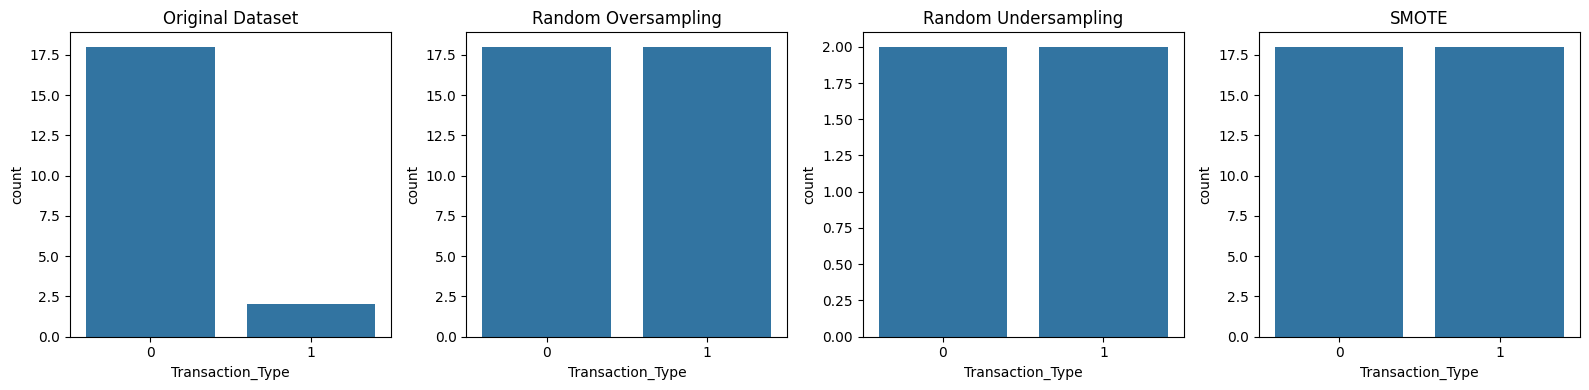

In [17]:
#Visualize Before and After Data Balancing
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

sns.countplot(x=y, ax=axes[0])
axes[0].set_title("Original Dataset")

sns.countplot(x=y_over, ax=axes[1])
axes[1].set_title("Random Oversampling")

sns.countplot(x=y_under, ax=axes[2])
axes[2].set_title("Random Undersampling")

sns.countplot(x=y_smote, ax=axes[3])
axes[3].set_title("SMOTE")

plt.tight_layout()
plt.show()

In [18]:
#In an actual Machine Learning project, follow this order:
#1. Load the dataset.
#2. Separate X and y.
#3. Split data into training and testing sets.
#4. Apply balancing techniques only to the training data.
#5. Train the ML model.
#6. Evaluate the model using the original, untouched testing data.
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler

# Split data first
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Apply oversampling only to training data
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train, y_train
)

# Check results
print("Training data before balancing:")
print(y_train.value_counts())

print("\nTraining data after balancing:")
print(y_train_balanced.value_counts())

print("\nTesting data:")
print(y_test.value_counts())

Training data before balancing:
Transaction_Type
0    14
1     2
Name: count, dtype: int64

Training data after balancing:
Transaction_Type
0    14
1    14
Name: count, dtype: int64

Testing data:
Transaction_Type
0    4
Name: count, dtype: int64


In [19]:
X = df.drop('Transaction_Type', axis=1)

y = df['Transaction_Type']

#split the datasets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#apply random over sampling
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_over, y_train_over = ros.fit_resample(
    X_train, y_train
)

#check result
print("Before Oversampling:")
print(y_train.value_counts())

print("\nAfter Oversampling:")
print(y_train_over.value_counts())

Before Oversampling:
Transaction_Type
0    14
1     2
Name: count, dtype: int64

After Oversampling:
Transaction_Type
0    14
1    14
Name: count, dtype: int64


In [22]:
#apply smote
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_over, y_train_over = ros.fit_resample(
    X_train, y_train
)
#check result
print("Before:")
print(y_train.value_counts())

print("\nAfter:")
print(y_train_over.value_counts())


Before:
Transaction_Type
0    14
1     2
Name: count, dtype: int64

After:
Transaction_Type
0    14
1    14
Name: count, dtype: int64


In [21]:
#under sampling
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = rus.fit_resample(
    X_train, y_train
)

#check result
print("Before Under Sampling:")
print(y_train.value_counts())

print("\nAfter Under Sampling:")
print(y_train_under.value_counts())

Before Under Sampling:
Transaction_Type
0    14
1     2
Name: count, dtype: int64

After Under Sampling:
Transaction_Type
0    2
1    2
Name: count, dtype: int64
